# This is the python file that filters through and cleans Water Bottle Inventory dataset

##### This dataset contains information regarding the locations of the current water bottle filling stations.

In [2]:
import pandas as pd
import matplotlib.pyplot as plt

In [3]:
df = pd.read_csv("Bottle Fillers Inventory.csv")
df.head(5)

,Address A,Address B,Floor,Description,Accessibility,Handicap Accessible,Space@Bu room,Quantity,Date Installed,Type,Walk-Thru Notes,Completed
0,100,Ashford St,First,"Hallway across from vending machines, across f...",Public,Yes,191,1.0,NaN,Combo Bottle Filler/Drinking Fountain,two additional drinking fountain locations in ...,1/5/2024
1,120,Ashford St,First,"Kitchenette, Room 116A",Restricted,Yes,116A,1.0,NaN,Office-Style Water Cooler,NaN,1/5/2024
2,120,Ashford St,Second,"Kitchenette, Room 222",Restricted,Yes,222,1.0,NaN,Office-Style Water Cooler,NaN,1/5/2024
3,8,St. Mary's Street,Basement,Hallway by bathrooms,NaN,NaN,B81,1.0,Dec-23,Combo Bottle Filler/Drinking Fountain,NaN,NaN
4,8,St. Mary's Street,First,Hallway by electrical room,NaN,NaN,181,1.0,NaN,NaN,NaN,NaN


First, we will take a look at the columns/variables.

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 212 entries, 0 to 211
Data columns (total 12 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Address A            207 non-null    object 
 1   Address B            207 non-null    object 
 2   Floor                207 non-null    object 
 3   Description          185 non-null    object 
 4   Accessibility        3 non-null      object 
 5   Handicap Accessible  3 non-null      object 
 6   Space@Bu room        188 non-null    object 
 7   Quantity             209 non-null    float64
 8   Date Installed       26 non-null     object 
 9   Type                 18 non-null     object 
 10  Walk-Thru Notes      29 non-null     object 
 11  Completed            3 non-null      object 
dtypes: float64(1), object(11)
memory usage: 20.0+ KB


Initial Questions To Consider:

This dataset contains 12 columns (variables).

This dataset has 212 rows (observations), indicating there are 212 locations/buildings.

There are categorical and numerical variables.

Categorical Variables: Floor, Accessibility, Handicap Accessible

Numerical Variables: Quantity

### Data Completion

Information on how much data is provided

In [5]:
df.isnull().sum()

Address A                5
Address B                5
Floor                    5
Description             27
Accessibility          209
Handicap Accessible    209
Space@Bu room           24
Quantity                 3
Date Installed         186
Type                   194
Walk-Thru Notes        183
Completed              209
dtype: int64

All of the columns contain some missing data points.

However, even if some of the data point is missing, we will try our best to extract meaningful results from it. Also, data is constantly getting updated according to the Sustainability team, so we can expect more information in the future.

### Data Cleaning

We can combine the Address A and Address B into one address.

In [6]:
df['Address'] = df['Address A'].astype(str) + ' ' + df['Address B'].astype(str)
df.head()

,Address A,Address B,Floor,Description,Accessibility,Handicap Accessible,Space@Bu room,Quantity,Date Installed,Type,Walk-Thru Notes,Completed,Address
0,100,Ashford St,First,"Hallway across from vending machines, across f...",Public,Yes,191,1.0,NaN,Combo Bottle Filler/Drinking Fountain,two additional drinking fountain locations in ...,1/5/2024,100 Ashford St
1,120,Ashford St,First,"Kitchenette, Room 116A",Restricted,Yes,116A,1.0,NaN,Office-Style Water Cooler,NaN,1/5/2024,120 Ashford St
2,120,Ashford St,Second,"Kitchenette, Room 222",Restricted,Yes,222,1.0,NaN,Office-Style Water Cooler,NaN,1/5/2024,120 Ashford St
3,8,St. Mary's Street,Basement,Hallway by bathrooms,NaN,NaN,B81,1.0,Dec-23,Combo Bottle Filler/Drinking Fountain,NaN,NaN,8 St. Mary's Street
4,8,St. Mary's Street,First,Hallway by electrical room,NaN,NaN,181,1.0,NaN,NaN,NaN,NaN,8 St. Mary's Street


Now, we can delete Address A and Address B columns and reorder it.

In [7]:
df.drop(['Address A', 'Address B'], axis=1, inplace=True)
df.head()

,Floor,Description,Accessibility,Handicap Accessible,Space@Bu room,Quantity,Date Installed,Type,Walk-Thru Notes,Completed,Address
0,First,"Hallway across from vending machines, across f...",Public,Yes,191,1.0,NaN,Combo Bottle Filler/Drinking Fountain,two additional drinking fountain locations in ...,1/5/2024,100 Ashford St
1,First,"Kitchenette, Room 116A",Restricted,Yes,116A,1.0,NaN,Office-Style Water Cooler,NaN,1/5/2024,120 Ashford St
2,Second,"Kitchenette, Room 222",Restricted,Yes,222,1.0,NaN,Office-Style Water Cooler,NaN,1/5/2024,120 Ashford St
3,Basement,Hallway by bathrooms,NaN,NaN,B81,1.0,Dec-23,Combo Bottle Filler/Drinking Fountain,NaN,NaN,8 St. Mary's Street
4,First,Hallway by electrical room,NaN,NaN,181,1.0,NaN,NaN,NaN,NaN,8 St. Mary's Street


In [8]:
cols = ['Address'] + [col for col in df.columns if col != 'Address']
df = df[cols]

In [9]:
df.head()

,Address,Floor,Description,Accessibility,Handicap Accessible,Space@Bu room,Quantity,Date Installed,Type,Walk-Thru Notes,Completed
0,100 Ashford St,First,"Hallway across from vending machines, across f...",Public,Yes,191,1.0,NaN,Combo Bottle Filler/Drinking Fountain,two additional drinking fountain locations in ...,1/5/2024
1,120 Ashford St,First,"Kitchenette, Room 116A",Restricted,Yes,116A,1.0,NaN,Office-Style Water Cooler,NaN,1/5/2024
2,120 Ashford St,Second,"Kitchenette, Room 222",Restricted,Yes,222,1.0,NaN,Office-Style Water Cooler,NaN,1/5/2024
3,8 St. Mary's Street,Basement,Hallway by bathrooms,NaN,NaN,B81,1.0,Dec-23,Combo Bottle Filler/Drinking Fountain,NaN,NaN
4,8 St. Mary's Street,First,Hallway by electrical room,NaN,NaN,181,1.0,NaN,NaN,NaN,NaN


Completed column is unimportant since most of the data points are missing and the completion date of installation of existing water bottle stations are not important. We can drop this column as well.

Date installed is also insignificant for the same reason.

The type of the water bottle filling station is also unimportant since we only care about the existence.

Majority of the two accessibility columns (Handicap Accessible, Accessibility) contain the value of NaN, which means that data does not exist in those columns. There are 212 observations but 209 of these columns do not exist, meaning that 98.58% of the data is missing. Therefore, it is better to omit these columns due to the missing data.

In [10]:
df.drop(['Date Installed', 'Type', 'Completed', 'Accessibility', 'Handicap Accessible'], axis=1, inplace=True)
df.head()

,Address,Floor,Description,Space@Bu room,Quantity,Walk-Thru Notes
0,100 Ashford St,First,"Hallway across from vending machines, across f...",191,1.0,two additional drinking fountain locations in ...
1,120 Ashford St,First,"Kitchenette, Room 116A",116A,1.0,NaN
2,120 Ashford St,Second,"Kitchenette, Room 222",222,1.0,NaN
3,8 St. Mary's Street,Basement,Hallway by bathrooms,B81,1.0,NaN
4,8 St. Mary's Street,First,Hallway by electrical room,181,1.0,NaN


## Now that we finished the mapping and cleaning of the dataset, we can now find the columns (variables) that we believe would help complete our main objective.

They are

1. Quantity - The number of water bottle filling stations per location.

In [11]:
df['Quantity'].value_counts()

Quantity
1.0      189
2.0       15
3.0        2
30.0       1
254.0      1
255.0      1
Name: count, dtype: int64

There are 189 buildings that have 1 water bottle filling station, 15 buildings that have 2 water bottle filling stations, and 2 buildings that have 3 water bottle filling stations, and 1 location that have 30, 254, and 255 water bottle filling stations. These are a combination of locations. For example, there are 30 water bottle stations in 700 commonwealth avenue from floor 5 to 18.

In [12]:
df[['Quantity']].describe()

,Quantity
count,209.000000
mean,3.655502
std,24.798728
min,1.000000
25%,1.000000
50%,1.000000
75%,1.000000
max,255.000000


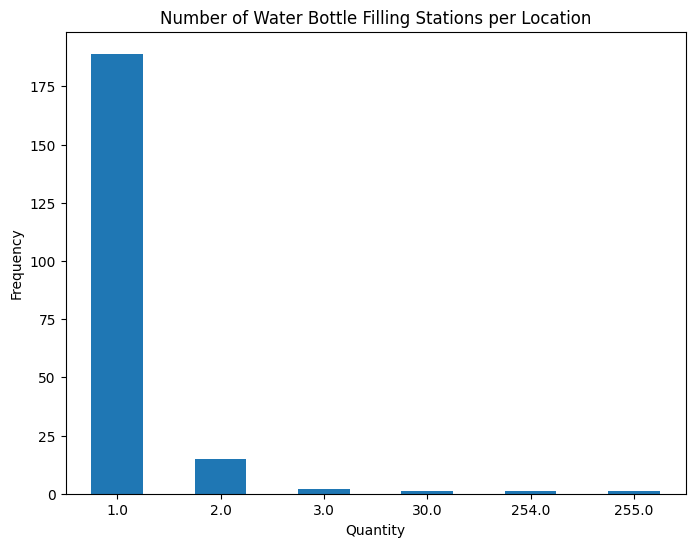

In [13]:
count = df['Quantity'].value_counts()
plt.figure(figsize=(8, 6))
count.plot(kind='bar')
plt.title('Number of Water Bottle Filling Stations per Location')
plt.xlabel('Quantity')
plt.ylabel('Frequency')
plt.xticks(rotation=0)
plt.show()

We do not need to filter any columns for this data since they are locations that already have water bottle filling stations.

With the full data, we will look at the cleaned dataset.

In [14]:
df.describe()

,Quantity
count,209.000000
mean,3.655502
std,24.798728
min,1.000000
25%,1.000000
50%,1.000000
75%,1.000000
max,255.000000


In [15]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 212 entries, 0 to 211
Data columns (total 6 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Address          212 non-null    object 
 1   Floor            207 non-null    object 
 2   Description      185 non-null    object 
 3   Space@Bu room    188 non-null    object 
 4   Quantity         209 non-null    float64
 5   Walk-Thru Notes  29 non-null     object 
dtypes: float64(1), object(5)
memory usage: 10.1+ KB


In [16]:
df.isnull().sum()

Address              0
Floor                5
Description         27
Space@Bu room       24
Quantity             3
Walk-Thru Notes    183
dtype: int64

In [17]:
from google.colab import files
df.to_csv('updated_Bottle_Fillers_Inventory.csv', index=False)
files.download('updated_Bottle_Fillers_Inventory.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>